In [1]:
#| include: false
import matplotlib.pyplot as plt
import numpy as np
import polars as pl

from utils.style import COLORS, CYCLE, apply_style

apply_style()
np.set_printoptions(precision=4, suppress=True, linewidth=110)
_ = pl.Config.set_float_precision(4)

::: callout-tip
## Learning outcomes

After this topic you should be able to: 

1.  Explain what statistics studies and distinguish descriptive statistics from statistical inference.
2.  Identify, in a concrete problem, the population, the individuals, the relevant subpopulations and the sample.
3.  Distinguish between a **parameter** and a **statistic**, and understand why a statistic varies from one sample to another.
4.  Classify a variable by its type and measurement scale, and know which operations and summaries make sense for each one ([part 2 of this topic](02-types-of-variables.ipynb)).
:::

## What is statistics?

Almost every relevant question in economics, health, engineering or the social sciences is about groups that are too large to be observed completely, or about phenomena that are subject to variability. What is the unemployment rate this quarter? Have house prices gone up? Does a new treatment reduce blood pressure? Is a production process within its tolerances? None of these questions can be answered with a single number. To answer them we have to **collect data, summarise them and draw conclusions that go beyond the observed data**, while quantifying the uncertainty of those conclusions.

::: callout-note
## Definition

**Statistics** is the discipline that studies methods for collecting, organising, summarising and analysing data, and for drawing valid conclusions and making reasonable decisions from them under uncertainty.
:::

Two ideas in this definition deserve attention:

- **Variability.** If all households had the same income, observing one would be enough. Statistics exists because individuals differ from each other. Its object of study is not each individual but the **distribution** of a characteristic in a group.
- **Uncertainty.** We almost never observe the whole group. Conclusions drawn from a part of it are subject to error, and statistics provides the tools to measure that error.

### Branches of statistics

It is common to distinguish two main branches, connected by probability theory:

- **Descriptive statistics** summarises and displays the observed data with tables, graphs and numerical measures. Its conclusions refer only to the available data. It is the subject of these notes.
- **Statistical inference** uses the data of a sample to draw conclusions about the population it comes from, together with a measure of their reliability.
- **Probability** is the language that makes inference possible: it models the randomness of sampling and quantifies the uncertainty of the conclusions.

Probability and inference are covered in their own subjects. Descriptive statistics, however, is not just a preliminary step: every data analysis begins, and often ends, with a careful description of the data.

```{mermaid}
%%| echo: false
%%| label: fig-cycle
%%| fig-cap: "Statistical reasoning. Probability describes how samples are generated from the population; inference goes the opposite way."
flowchart LR
    P["Population<br/>(unknown parameters)"] -- "sampling<br/>(probability)" --> M["Sample<br/>(observed data)"]
    M -- "descriptive<br/>statistics" --> R["Summaries<br/>(statistics)"]
    R -- "statistical<br/>inference" --> P
```

### Statistics in practice

Some examples of how statistics is used:

- **Official statistics.** Many of the indicators reported in the press are estimates obtained from samples. In Spain, the unemployment rate comes from the *Labour Force Survey* (EPA) of the National Statistics Institute (INE), which interviews tens of thousands of households every quarter. The Consumer Price Index is based on a sample of prices of products and outlets, and income and poverty figures come from the *Survey on Income and Living Conditions*.
- **Economics and finance.** Series of GDP, inflation, interest rates or stock prices are analysed to describe their evolution, measure risks and build forecasts.
- **Health.** Clinical trials compare treatments on samples of patients, and epidemiological surveys estimate the prevalence of diseases and risk factors.
- **Engineering and industry.** Quality control, reliability studies and the monitoring of production processes rely on samples of products and measurements.
- **Policy evaluation and social sciences.** Does a training programme improve the employment of its participants? Answering requires comparing groups and separating the effect of the programme from random variability.

::: callout-important
## An indicator is an estimate

When the INE publishes an unemployment rate of 11.5 %, it has not asked the whole labour force: it has estimated that value from a sample. This is why it also publishes **sampling errors**, and why a change of one tenth of a point between two quarters may not be significant.
:::

## Populations, subpopulations, individuals and samples

### Population and individuals

::: callout-note
## Definition

- **Population** (or universe): the set of all the elements whose characteristics we want to study. Its number of elements, the **population size**, is denoted by $N$.
- **Individual** (or statistical unit): each element of the population.
:::

Individuals need not be people. They can be households, firms, municipalities, transactions, products, patients or time periods. Defining the population precisely is the first step of any study, and requires specifying **who**, **where** and **when**.

::: callout-tip
## Example

In the Spanish Labour Force Survey, the population of interest is people aged 16 or over living in family dwellings in Spain during the reference quarter. People living in collective establishments (care homes, barracks…) are excluded. This decision affects what the indicator measures.
:::

### Subpopulations

::: callout-note
## Definition

A **subpopulation** is a subset of the population defined by one or more characteristics of its individuals.
:::

Subpopulations allow us to analyse heterogeneity: the unemployment rate of young people, the mean income of households in Andalusia, or the sales of small firms. When the population is divided into disjoint subpopulations that cover it completely (for example, by region), they are called **strata**.

### Census and sample

::: callout-note
## Definition

- **Census**: a study in which all the individuals of the population are observed.
- **Sample**: the subset of the population that is actually observed. Its number of elements, the **sample size**, is denoted by $n$.
:::

Why not always observe the whole population? There are several reasons:

- **Cost and time.** Interviewing every household in Spain every quarter would be impossible. A well-designed sample gives very precise results for a fraction of the cost.
- **Infinite or hypothetical populations.** The customers a firm will have next year, or all the possible realisations of a process, cannot be listed.
- **Destructive testing.** To check the lifetime of batteries they must be run down. A census would leave the firm with nothing to sell.
- **Quality.** A census with many poorly trained interviewers can contain more errors than a carefully conducted sample.

### Representative samples and random sampling

A sample is only useful if it allows us to draw conclusions about the population, that is, if it is **representative**: its composition reproduces that of the population, apart from variations due to chance. The way to guarantee this is to select it **at random**, with a known probabilistic mechanism.

::: callout-note
## Definition

A **simple random sample** of size $n$ from a finite population of size $N$ is a sample obtained in such a way that every possible subset of $n$ individuals has the same probability of being chosen, 
$$
\frac{1}{\binom{N}{n}} .
$$ 
In particular, every individual has the same probability, $n/N$, of being in the sample.
:::

There are other sampling designs, such as stratified or cluster sampling, which official surveys combine to gain precision and reduce costs. All of them share one principle: **selection is decided by chance, not by the researcher or by the respondent**.

::: callout-note
## Historical note: the *Literary Digest* poll (1936)

Before the 1936 US presidential election, the magazine *Literary Digest* mailed about 10 million straw-vote ballots and received some 2.4 million replies. It predicted a clear victory for the Republican Alf Landon, but Franklin D. Roosevelt won by a landslide. The addresses had been taken largely from lists of telephone subscribers and car owners, groups with above-average income during the Great Depression, and only the most motivated recipients replied [@squire1988]. The same year, George Gallup correctly predicted Roosevelt's victory with a far smaller sample chosen to mirror the composition of the electorate, and the episode made the reputation of scientific polling.

A huge but **biased** sample does not correct the bias. A small but **random** sample allows reliable inference.
:::

Other common biases in real data:

- **Non-response bias**: very high-income households tend to answer surveys less often.
- **Survivorship bias**: studying only the firms or investment funds that are still active overstates their average return.
- **Self-selection**: open web surveys collect the opinion of those who decide to take part, not that of the population.

### Parameters and statistics

This distinction underlies all of statistics.

::: callout-note
## Definition

- A **parameter** is a numerical measure describing a characteristic of the **population**. It is a fixed value, but usually unknown.
- A **statistic** is a numerical measure computed from the data of a **sample**. It is known once the sample has been observed, but it **varies from one sample to another**.
:::

We use the usual notation: Greek letters for parameters and Latin letters for statistics.

| Quantity | Population (parameter) | Sample (statistic) |
|------------------------|------------------------|------------------------|
| Size | $N$ | $n$ |
| Mean | $\mu = \dfrac{1}{N}\displaystyle\sum_{i=1}^{N} x_i$ | $\bar{x} = \dfrac{1}{n}\displaystyle\sum_{i=1}^{n} x_i$ |
| Variance | $\sigma^2$ | $s^2$ |
| Proportion | $p$ | $\hat{p}$ |

: Notation for parameters and statistics.

Let us see the difference with an experiment. We use the data of the INE *Household Budget Survey* (EPF) of 2025, which records the expenditure of almost 20,000 households living in Spain (`data/processed/epf/households.csv`). Suppose, **for illustration only**, that these households make up the whole population. Then the mean annual expenditure of all of them is a parameter, $\mu$, which we can compute exactly:

In [2]:
population = pl.read_csv("data/processed/epf/households.csv")

mu = population["exp_total"].mean()
print(f"N = {population.height:,} households  ·  μ = {mu:,.0f} €")

N = 19,703 households  ·  μ = 35,705 €


(In reality, these households are themselves a sample from the roughly 19.6 million households in Spain, as the column `weight` tells us. We come back to this in [Topic 7](../07-data-quality.qmd).)

Now we draw several simple random samples of size $n = 30$ and compute the sample mean expenditure $\bar{x}$ in each one:

In [3]:
means = [
    population.sample(n=30, seed=seed)["exp_total"].mean()
    for seed in range(5)
]
pl.DataFrame({"sample": range(1, 6), "sample mean": means})

sample,sample mean
1,"31,616.2"
2,"33,021.3"
3,"38,543.0"
4,"34,791.1"
5,"33,754.1"


Each sample gives a different value of $\bar{x}$, and none of them equals $\mu$ exactly. If we repeat the experiment many times, we can see how the statistic is distributed:

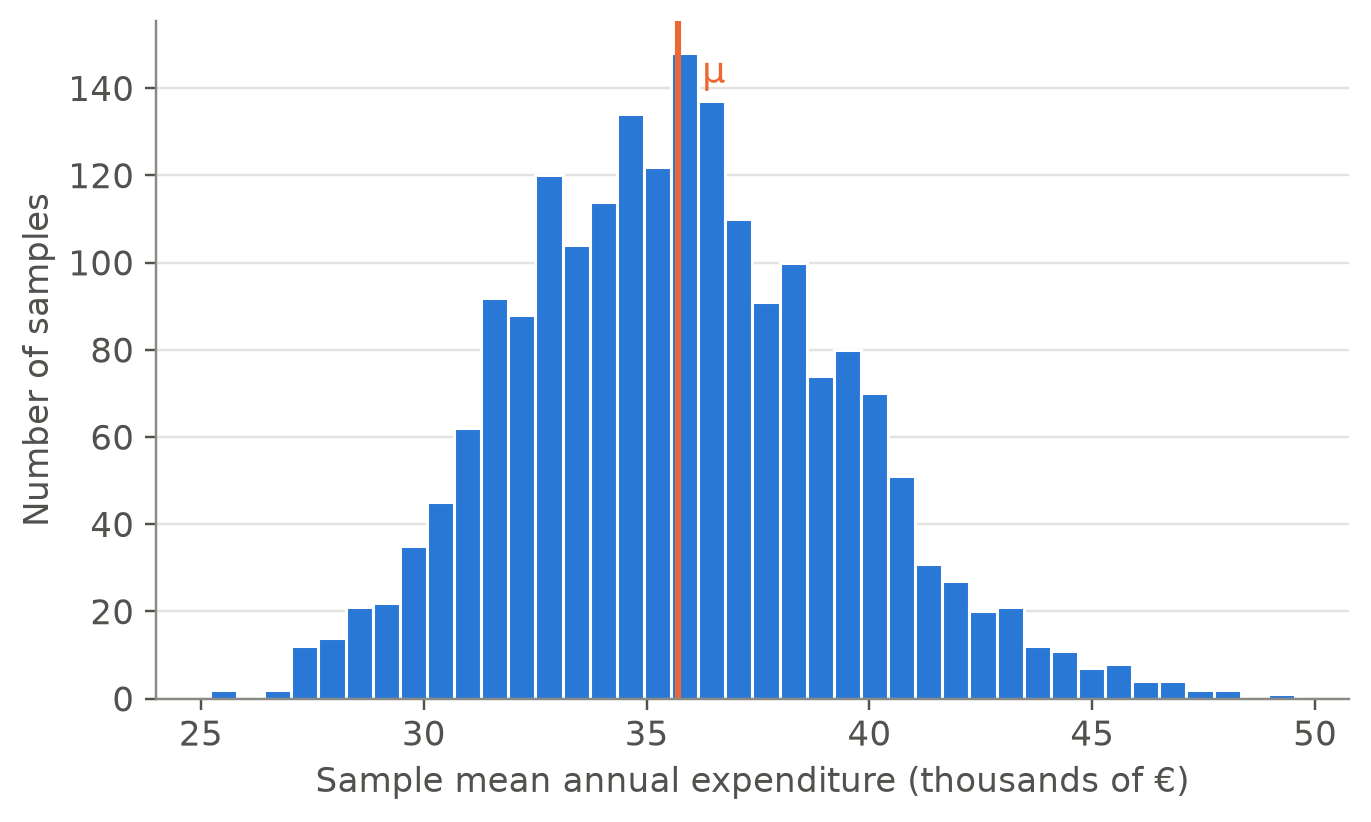

The mean of th 2000 means is: 35695.81, which differs in 9.36 units from the population mean, a 0.03%.


In [4]:
#| label: fig-sample-means
#| fig-cap: "Sample means of 2,000 simple random samples of size 30. The vertical line marks the population parameter μ."
rng = np.random.default_rng(1)
expenditure = population["exp_total"].to_numpy()
means = [rng.choice(expenditure, size=30, replace=False).mean() for _ in range(2_000)]

fig, ax = plt.subplots()
ax.hist(np.array(means) / 1000, bins=40, color=COLORS["blue"],
        edgecolor="white", linewidth=1)
ax.axvline(mu / 1000, color=COLORS["orange"], linewidth=2)
ax.text(mu / 1000, ax.get_ylim()[1] * 0.95, "  μ", color=COLORS["orange"],
        va="top", fontsize=12)
ax.set_xlabel("Sample mean annual expenditure (thousands of €)")
ax.set_ylabel("Number of samples")
plt.show()
print(f"The mean of th 2000 means is: {round(np.mean(means), 2)}, which differs in {round(np.abs(mu - np.mean(means)), 2)} units from the population mean, a {round((np.abs(mu - np.mean(means)) / mu) * 100, 2)}%.")

@fig-sample-means anticipates central ideas of statistical inference:

- The statistic $\bar{x}$ is a **random variable**: its value depends on the sample that chance has selected.
- Its values are concentrated around the parameter $\mu$, so there is no systematic error.
- Its spread measures the **sampling error**, which decreases as $n$ increases (@exr-proportion).

::: callout-caution
## Why is this only an illustration?

In practice **we never know** $\mu$. If we could compute it, we would not need samples. Here we have treated the data as a population in order to compare the statistic with the parameter, which is impossible in a real study.
:::

Subpopulations have their own parameters, for example the mean expenditure of the households of each region:

In [5]:
population\
    .group_by("region")\
    .agg(N=pl.len(), mean_expenditure=pl.col("exp_total").mean())\
    .sort("mean_expenditure", descending=True)

region,N,mean_expenditure
Madrid,1755,"42,973.6"
Catalonia,1440,"40,411.3"
Basque Country,2059,"40,080.9"
Balearic Islands,506,"38,298.5"
Melilla,114,"37,051.3"
Aragon,954,"36,087.2"
Navarre,575,"36,029.1"
Cantabria,690,"35,646.2"
Valencian Community,1706,"35,372.0"
Ceuta,82,"35,284.3"


## Exercises

::: {#exr-supermarket}
## Population, sample and parameter

A supermarket chain wants to know the mean amount spent per purchase by its customers in the Madrid region during March. To do so, it records the amount of 1,200 receipts selected at random among all those issued that month in its stores in the region.

a)  Identify the population, the individual, the sample and the sizes $N$ and $n$ (if known).
b)  What is the parameter of interest? Which statistic would you use to estimate it?
c)  The firm wants to compare the stores in the city of Madrid with those in the rest of the region. Which concept describes these two groups?
:::

::: {.callout-tip collapse="true"}
## Solution

a)  Population: all the receipts issued in March in the chain's stores in the Madrid region. Individual: each receipt, that is, each purchase, not each customer. Sample: the 1,200 selected receipts, $n = 1\,200$. $N$ is the total number of receipts of the month, known to the firm even if it is not given.

b)  Parameter: the mean amount per purchase in the population, $\mu$. Statistic: the sample mean $\bar{x}$ of the 1,200 amounts.

c)  They are two subpopulations. Since they are disjoint and cover the whole population, they are strata.
:::

::: {#exr-web-survey}
## A web survey

An online newspaper reports that "78 % of Spaniards support a four-day working week", according to a survey answered by 25,000 readers on its website. Discuss whether this result can be generalised to the Spanish population. Would the situation improve if 250,000 readers had answered?
:::

::: {.callout-tip collapse="true"}
## Solution

It cannot be generalised. The sample is not random but **self-selected**: it consists of readers of that newspaper, with internet access, who decide to take part. They are probably those with the strongest opinions on the subject. Nothing guarantees that their composition resembles that of the population. Increasing the number of answers does not help: as with the *Literary Digest*, a larger sample with the same bias only estimates the wrong quantity more precisely.
:::

::: {#exr-proportion}
## Sampling variability of a proportion (with Python)

Treating again the households of the EPF as if they were the population:

a)  Compute the population proportion $p$ of households that rent their home.
b)  Draw 1,000 simple random samples of size $n = 50$ and compute the sample proportion $\hat{p}$ in each one. Plot their histogram together with $p$.
c)  Repeat b) with $n = 200$. What changes?
:::

::: {.callout-tip collapse="true"}
## Solution

Sample deviation of p_hat for n=50: 0.048
Sample deviation of p_hat for n=200: 0.026


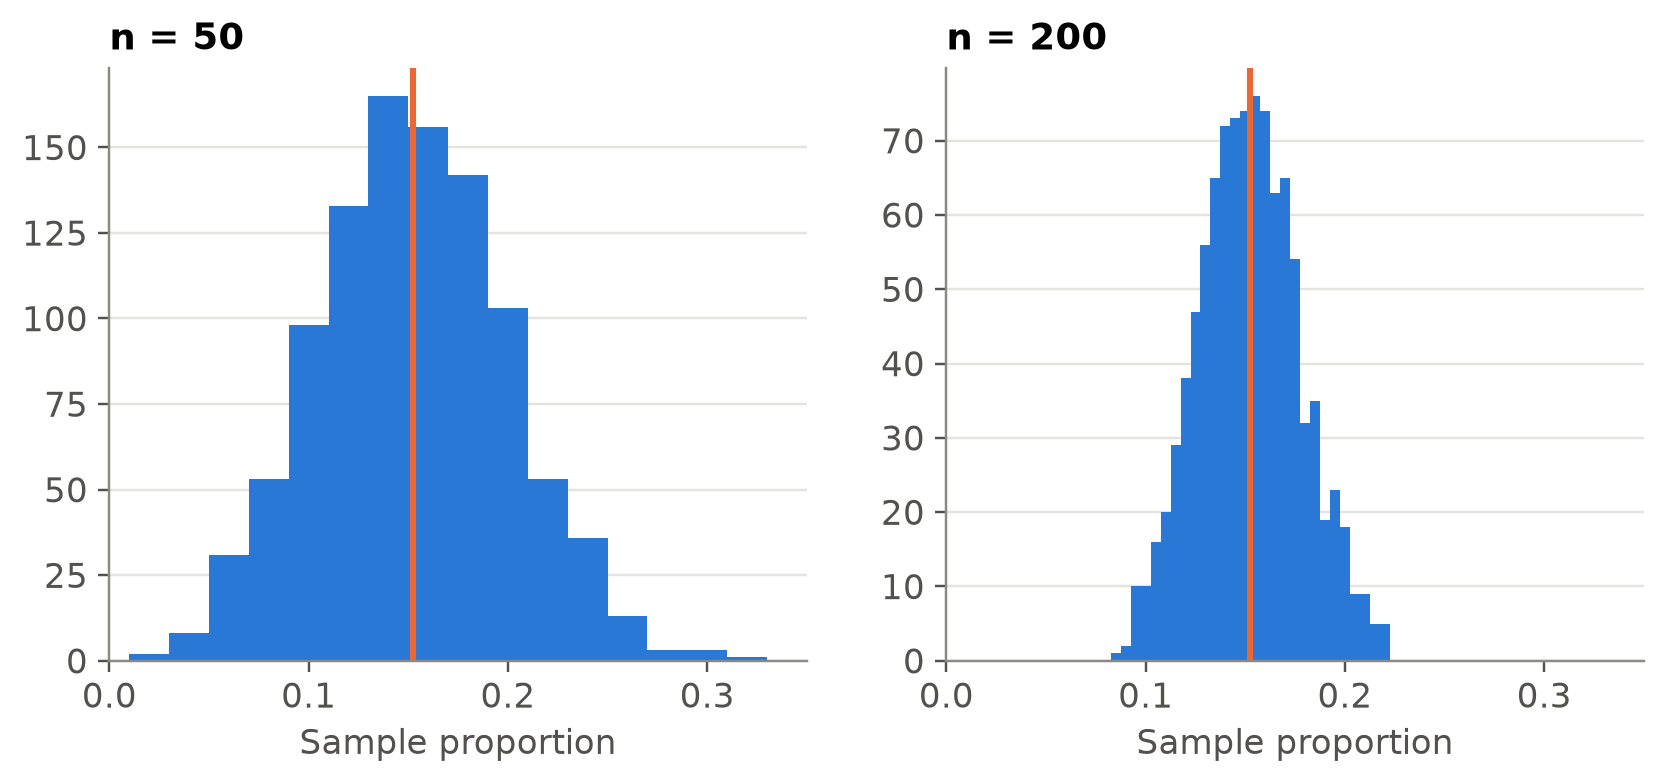

Population p = 0.152


In [6]:
rented = (population["tenure_group"] == "Rented").to_numpy()
p = rented.mean()

rng = np.random.default_rng(2026)
fig, axes = plt.subplots(1, 2, figsize=(9, 3.5), sharex=True)
for ax, n in zip(axes, [50, 200]):
    p_hat = [rng.choice(rented, size=n, replace=False).mean() for _ in range(1_000)]
    # p̂ only takes the values k/n: one bin per possible value
    edges = (np.arange(n + 2) - 0.5) / n
    ax.hist(p_hat, bins=edges, color=COLORS["blue"])
    ax.axvline(p, color=COLORS["orange"], linewidth=2)
    ax.set_title(f"n = {n}")
    ax.set_xlabel("Sample proportion")
    ax.set_xlim(0, 0.35)
    print(f"Sample deviation of p_hat for n={n}: {round(np.std(p_hat), 3)}")
plt.show()
print(f"Population p = {p:.3f}")

Both distributions are centred on $p$, but with $n = 200$ the spread is much smaller: the sample proportions stay closer to the parameter. The sampling error decreases as the sample size increases.
:::

## References {.unnumbered}

::: {#refs}
:::